In [ ]:
import numpy as np         # biblioteca que auxilia a fazer contas
import matplotlib.pyplot as plt # biblioteca para plotar graficos

\begin{align}
EDO \ :\\ \frac{dx_0}{dt} = x_1 \,\,  \\
\, \, \frac{dx_1}{dt} = -9sen(x_0)-\frac{1}{5}x_1
\end{align}

In [ ]:
def ff(t,x):#definindo a edo
    dxdt = x[1]
    dydt = -9*np.sin(x[0])-1/5*x[1]
    return np.array([dxdt,dydt])# retornando a soluçao

In [ ]:
def rungeKuta4(x0,y0,a,b,n,f):
    h=(b-a)/n#calculando o h que é o tamanho do passo
    xi = np.zeros(n)#criando um vetor de zeros do tamanho n
    yi = []# inicializando uma lista
    #nesse for começa o runge kuta. Basta consultar o livro do boyce  capitulo 8.3 para mais detalhes
    for i in range(n):
        k1 = f(x0, y0)
        k2 = f(x0 +  h/2, y0 + h/2*k1)
        k3 = f(x0 +  h/2, y0 + h/2*k2)
        k4 =f(x0 +  h, y0 + h*k3)
        yk = y0 + (h/6) *(k1 +  2*k2 + 2*k3 + k4)
        x0 = x0 + h# atualizando o valor de x0
        y0=yk # atualizando o valor de y0

        xi[i] =x0
        yi.append(yk)#adicionando cada soluçao na lista
        #print(f"({(x0), y0})")
    return xi,yi#xi é a malha e yi é uma lista nx2 onde cada coluna é o vetor solução

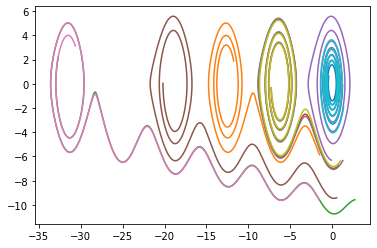

In [ ]:
#imprimindo o retrato de fase
#para imprimir o retrato de fase vamos rodar o runge-kuta umas 10 vezes alterando o chute inicial
for i in range(10):

    a=0#definindo a malha
    b=10#definindo a malha
    n=1000# definindo o quanto que será repartido a malha
    x0=np.array(0)# condiçao inicial
    y0=np.array([np.random.rand(1)*2*np.pi-np.pi,np.random.rand(1)*-10])# condição inicial
    x,y = rungeKuta4(x0,y0,a,b,n,ff)
    a=[]#criando uma lista vazia para armazenar o primeiro vetor de soluçao
    b= []#criando uma lista vazia para armazenar o segundo vetor de soluçao

    #esse for é para separar a solução em 2 listas para plotar
    for i in range(len(y)):
        a.append(y[i][0])
        b.append(y[i][1])
    plt.plot(a,b)# plota o grafico
plt.savefig("retrato de fase")   #salva a figura